# Entropy Calculation

# Entropy Calculation

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

from qss.solver_options import brent_defaults
from qss.chemical_potential import chemical_potential
from qss.entropy import entropy
from qss.distributions import prepare_2D_lattice_data, DistType
import tools.scientific_plot_v2 as sp
plotter = sp.ScientificPlotter()

## 2D Lattice

In [ ]:
N = 100
t = -1
# t_prim = 0.25
t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Chemical Potential

In [ ]:
# Band filling values
n_min = 0.01
n_max = 0.99
n_count = 40


# Beta values
beta_min = 0
beta_max = 2
beta_count = 3

distros = [DistType.FD, DistType.FLB, DistType.NFL, DistType.NFLB, DistType.SSL]  # ND
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
beta = np.logspace(beta_min, beta_max, beta_count, dtype=np.float64)  # NB
H_a = np.array([0.0], dtype=np.float64) # NH

In [ ]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=2.0,
    initial_step=1.0,  
    max_expands=164,
    max_iters=5000      
)
native_opts= py_opts.to_qss()

mu_df = chemical_potential(
    distros=distros,
    n_vals=n,
    beta_vals=beta,
    H_a_vals=H_a,
    N=N,
    E=e_k,
    solver_opts=native_opts,
    x0=-1.0,
    a0=-5.0,
    b0=5.0,
)
k_BT = 1/beta

## Entropy

In [ ]:
entropy_df = entropy(mu_df, e_k)
entropy_df.to_csv("chemical_potential_results.csv")
entropy_df

mu  iterations  converged      residual  \
distro n        k_BT H_a                                                  
FD     0.010000 1.00 0.0 -6.941937          20       True  3.939434e-09   
       0.035128 1.00 0.0 -5.626782          23       True  1.868425e-08   
       0.060256 1.00 0.0 -5.028113          23       True  1.577730e-08   
       0.085385 1.00 0.0 -4.620228          23       True  7.883217e-09   
       0.110513 1.00 0.0 -4.302731          21       True  8.987381e-08   
...                            ...         ...        ...           ...   
SSL    0.889487 0.01 0.0  2.661808          23       True  2.869525e-08   
       0.914615 0.01 0.0  2.936411          23       True  4.789963e-08   
       0.939744 0.01 0.0  3.222435          23       True  2.279705e-08   
       0.964872 0.01 0.0  3.521440          23       True  9.836539e-08   
       0.990000 0.01 0.0  3.842800          16       True  2.820890e-09   

                           entropy  
distro n        k_BT H_a            
FD     0.010000 1.00 0.0  0.050820  
       0.035128 1.00 0.0  0.135552  
       0.060256 1.00 0.0  0.201223  
       0.085385 1.00 0.0  0.256832  
       0.110513 1.00 0.0  0.305640  
...                            ...  
SSL    0.889487 0.01 0.0  0.615984  
       0.914615 0.01 0.0  0.633676  
       0.939744 0.01 0.0  0.651015  
       0.964872 0.01 0.0  0.669196  
       0.990000 0.01 0.0  0.687490  

[600 rows x 5 columns]

#### $\frac{S} {k_B N} = f(n)$

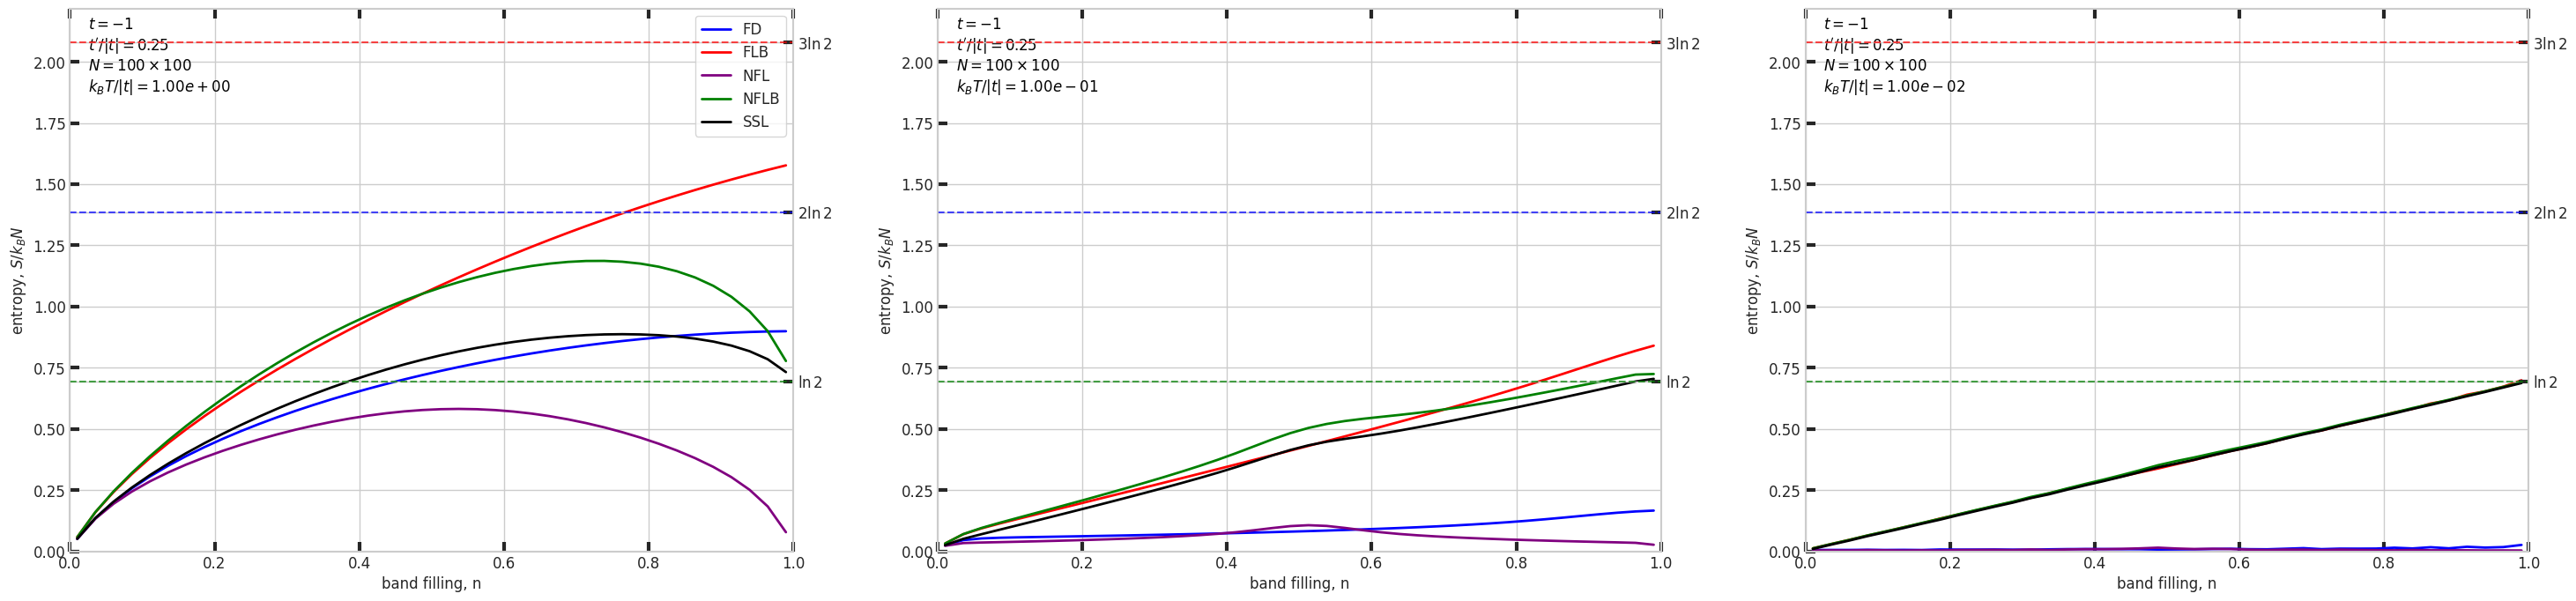

In [ ]:
H_a_plot = H_a[0] 
beta_plot = 1/k_BT
distro = ["FD","FLB","NFL", "NFLB", "SSL"]
# Plot
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="n",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="beta",
    subplots_vals=beta_plot,
    cols=3,
    figsize=(12, 8),
    show_log_vals=True,
    ylims=(0, 2.5),
    xlims=(0, 1)
)
plt.show()